In [48]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV 
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import umap
import math
import matplotlib.patches as mpatches

# Wczytanie danych i inspekcja

In [49]:
# Wczytanie danych i czyszczenie
df = pd.read_csv("output/features/all_features.csv")

#Inspekcja danych ile mamy NA
df.isna().sum()

gbifID                        0
decimalLongitude              0
decimalLatitude               0
wc2.1_30s_bio_1               0
wc2.1_30s_bio_10              0
wc2.1_30s_bio_11              0
wc2.1_30s_bio_12              0
wc2.1_30s_bio_13              0
wc2.1_30s_bio_14              0
wc2.1_30s_bio_15              0
wc2.1_30s_bio_16              0
wc2.1_30s_bio_17              0
wc2.1_30s_bio_18              0
wc2.1_30s_bio_19              0
wc2.1_30s_bio_2               0
wc2.1_30s_bio_3               0
wc2.1_30s_bio_4               0
wc2.1_30s_bio_5               0
wc2.1_30s_bio_6               0
wc2.1_30s_bio_7               0
wc2.1_30s_bio_8               0
wc2.1_30s_bio_9               0
Aspect                       19
Curvature                    26
DEM                          13
NDVI                         14
EVI                          14
SAVI                         14
NDWI                         14
BSI                          14
Silicates                    14
Carbonat

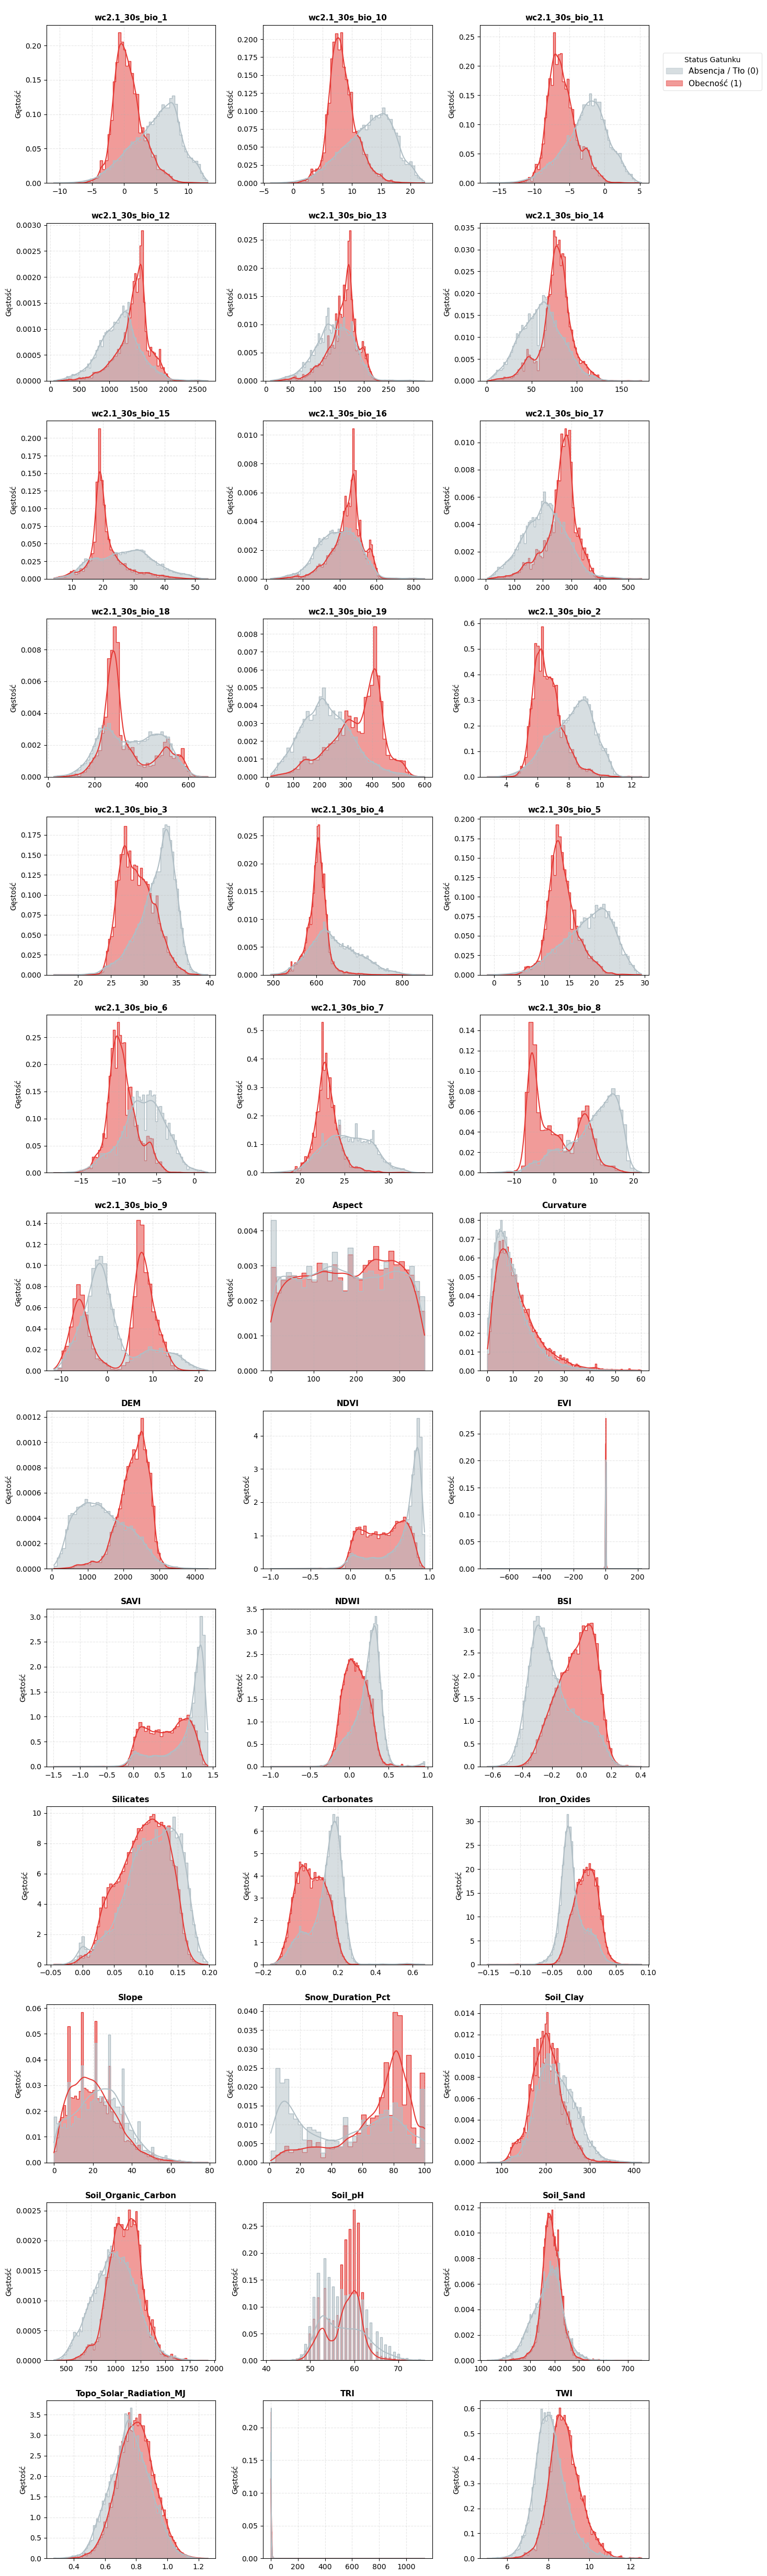

In [50]:
import math
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns



# Wykluczmay kolumny
wykluczone_kolumny = [
    "gbifID",
    "decimalLongitude",
    "decimalLatitude",
    "Cluster",
    "true_present"
]

# Tworzenie kolumny z informacją o pseudoabsencji (0 = pseudo, 1 = prawdziwa obecność)
df["true_present"] = df["gbifID"].str.contains("pseudo", case=True).map({True: 0, False: 1})

cechy_do_wykresu = [
    col
    for col in df.select_dtypes(include=[np.number]).columns
    if col not in wykluczone_kolumny
]

# Wyliczmay liczbę wykresów i układ siatki
n_cols = 3
n_rows = math.ceil(len(cechy_do_wykresu) / n_cols)

# Inicjalizacja płótna
fig, axes = plt.subplots(
    n_rows, n_cols, figsize=(n_cols * 5, n_rows * 3.8), sharey=False
)
axes = axes.flatten()

# Paleta kolorów (szary dla tła, czerwony dla obecności)
kolory = {0: "#b0bec5", 1: "#e53935"}

# Pętla rysująca histogramy dla surowych danych
for i, col in enumerate(cechy_do_wykresu):
    ax = axes[i]

    sns.histplot(
        data=df,
        x=col,
        hue="true_present",
        palette=kolory,
        alpha=0.5,
        kde=True,
        element="step",
        stat="density",
        common_norm=False,
        legend=False,  # Brak małych legend w okienkach
        ax=ax,
    )

    # Stylizacja pojedynczego wykresu
    ax.set_title(f"\n{col}", fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Gęstość")
    ax.grid(True, linestyle="--", alpha=0.3)



# Tworzenie jednej, czystej legendy globalnej po prawej stronie
legenda_absencja = mpatches.Patch(
    color=kolory[0], alpha=0.5, label="Absencja / Tło (0)"
)
legenda_obecnosc = mpatches.Patch(
    color=kolory[1], alpha=0.5, label="Obecność (1)"
)

leg = fig.legend(
    handles=[legenda_absencja, legenda_obecnosc],
    loc="upper right",
    bbox_to_anchor=(0.98, 0.98),
    title="Status Gatunku",
    fontsize=11,
    frameon=True,
    facecolor="white",
    edgecolor="#e0e0e0",
)


# Zachowanie bezpiecznego marginesu na legendę z prawej strony
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.show()

In [51]:
df = df.drop(columns="true_present")

# DEM

In [52]:
#Usuwamy DEM aby uniezależnić model od wysokości, która jest silnie skorelowana z innymi warstwami
df = df.drop(columns="DEM")

## Bioclim 
BIOCLIM (Bioclimatic variables) to zestaw 19 globalnych zmiennych klimatycznych, wyprowadzonych z miesięcznych pomiarów temperatury i opadów. Zamiast prostych średnich, odzwierciedlają one uwarunkowania biologiczne i środowiskowe istotne dla życia organizmów.

        bio1="Annual Mean Temperature (°C)",
        bio2="Mean Diurnal Range",
        bio3="Isothermality",
        bio4="Temperature Seasonality",
        bio5="Max Temp Warmest Month",
        bio6="Min Temp Coldest Month",
        bio7="Temp Annual Range",
        bio8="Mean Temp Wettest Quarter",
        bio9="Mean Temp Driest Quarter",
        bio10="Mean Temp Warmest Quarter",
        bio11="Mean Temp Coldest Quarter",
        bio12="Annual Precipitation (mm)",
        bio13="Precipitation Wettest Month",
        bio14="Precipitation Driest Month",
        bio15="Precipitation Seasonality",
        bio16="Precipitation Wettest Quarter",
        bio17="Precipitation Driest Quarter",
        bio18="Precipitation Warmest Quarter",
        bio19="Precipitation Coldest Quarter"
        
Są one mocno z sobą skorelowane. Będziemy musieli wybrać do modelu odpowiednie.

            feature       VIF
0  wc2.1_30s_bio_10  2.746000
1   wc2.1_30s_bio_6  2.522635
2   wc2.1_30s_bio_9  1.142402


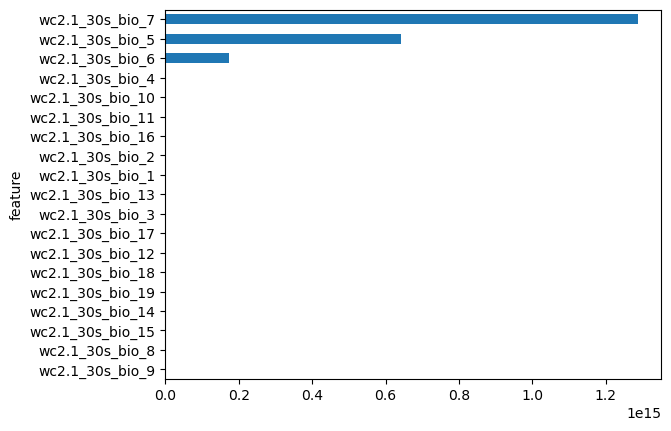

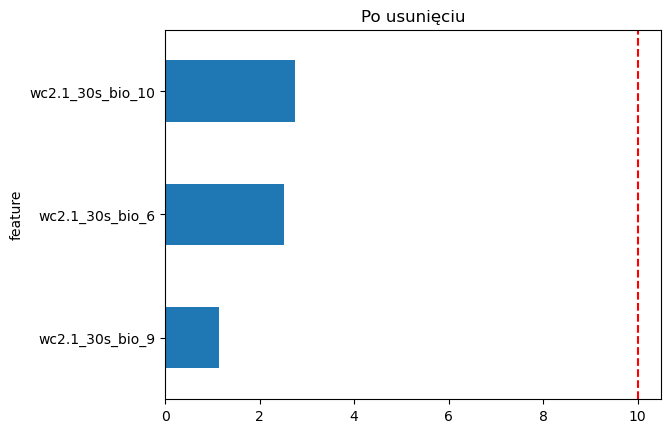

In [53]:


def calculate_vif_wc(df):
    vif_data = pd.DataFrame()
    wybrane_kolumny = df.columns[df.columns.str.contains("wc", case=False)]
    features = df[wybrane_kolumny]
    vif_data["feature"] = features.columns
    vif_data["VIF"] = [variance_inflation_factor(features.values, i) for i in range(features.shape[1])]
    vif_df = vif_data.sort_values(by="VIF", ascending=False).reset_index(drop=True)
    return vif_df

# Sprawdzamy VIF

vif_df = calculate_vif_wc(df)
vif_df.sort_values(by="VIF").plot(
    kind="barh", x="feature", y="VIF", legend=False
)
#Wyrzucamy warstwy bioklimatyczne o njwiększym VIF ale takie które mają sens biologiczny
df_wc=df.drop(columns=["wc2.1_30s_bio_7", 
                       "wc2.1_30s_bio_1", 
                       "wc2.1_30s_bio_12", 
                       "wc2.1_30s_bio_4", 
                       "wc2.1_30s_bio_5", 
                       "wc2.1_30s_bio_16",
                       "wc2.1_30s_bio_11",
                       "wc2.1_30s_bio_14",
                       "wc2.1_30s_bio_13",
                       "wc2.1_30s_bio_3",
                       "wc2.1_30s_bio_17",
                       "wc2.1_30s_bio_8",
                       "wc2.1_30s_bio_2",
                       "wc2.1_30s_bio_19",
                       "wc2.1_30s_bio_15",
                       "wc2.1_30s_bio_18"])
vif_df = calculate_vif_wc(df_wc)
print(vif_df)
vif_df.sort_values(by="VIF").plot(kind="barh", x="feature", y="VIF", legend=False, title = "Po usunięciu")
plt.axvline(x=10, color="r", linestyle="--")
df=df_wc

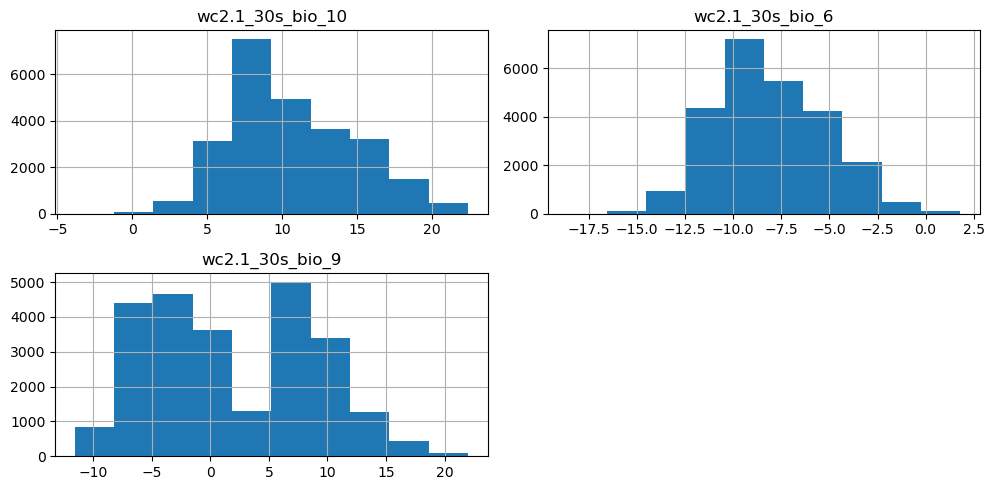

In [54]:
#Kolumny WC
wybrane_kolumny = df.columns[df.columns.str.contains("wc", case=False)]

#Histogramy dla WC
df[wybrane_kolumny].hist(bins=10, figsize=(10, 5))

#Wyświetlenie wykresu
plt.tight_layout()
plt.show()

## Snow Duration
Liczba dni w roku w których wystepuje pokrywa śnieżna. Dane z satelity Sentiel-1, pobrane z GEE.

<Axes: >

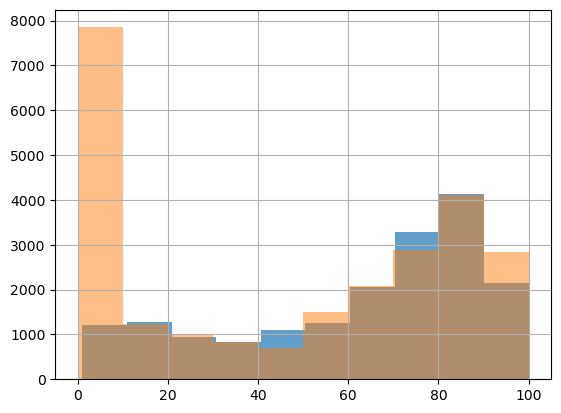

In [55]:
df["Snow_Duration_Pct"].hist(alpha=0.7)
df['Snow_Duration_Pct'] = df['Snow_Duration_Pct'].fillna(0)
#Uzupełnienie brakujących wartości w kolumnie "Snow_Duration_Pct" wartością 0. 
#"0" biologicznie oznacza brak opadów więc jest to legalne
df["Snow_Duration_Pct"].hist(alpha=0.5)

## Soil
Warstwy glebowe sa ważne bo te rośliny rosnać często na wapieniu lub granicie

In [56]:
def calculate_vif(data_frame, lista_kolumn):
    vif_data = pd.DataFrame()

    # Wycinamy tylko te, które istnieją w df, i usuwamy braki danych
    istniejace_kolumny = [col for col in lista_kolumn if col in data_frame.columns]
    X = data_frame[istniejace_kolumny].dropna()

    vif_data["feature"] = X.columns
    vif_data["VIF"] = [
        variance_inflation_factor(X.values, i) for i in range(X.shape[1])
    ]
    return vif_data.sort_values(by="VIF", ascending=False).reset_index(
        drop=True
    )

In [57]:
df.isna().sum()
#Sporo warstw glebowych ma NA. Dzieje się tak jeśli występują na głównie na skale dla której nie mamy danych


gbifID                       0
decimalLongitude             0
decimalLatitude              0
wc2.1_30s_bio_10             0
wc2.1_30s_bio_6              0
wc2.1_30s_bio_9              0
Aspect                      19
Curvature                   26
NDVI                        14
EVI                         14
SAVI                        14
NDWI                        14
BSI                         14
Silicates                   14
Carbonates                  14
Iron_Oxides                 14
Slope                       19
Snow_Duration_Pct            0
Soil_Clay                  819
Soil_Organic_Carbon        818
Soil_pH                    819
Soil_Sand                  819
Topo_Solar_Radiation_MJ     19
TRI                         13
TWI                         19
dtype: int64

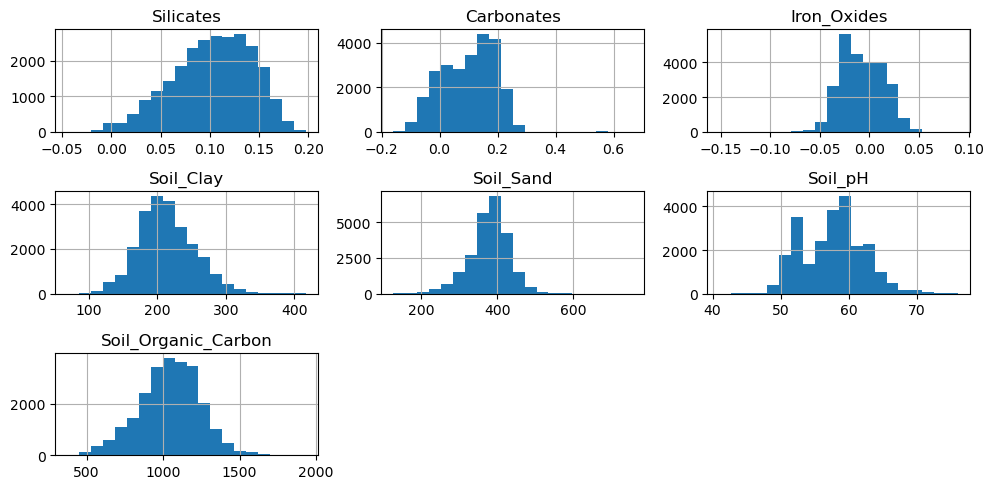

In [58]:
#Kolumny Soil
sklad_mineralny = [
    "Silicates",
    "Carbonates",
    "Iron_Oxides",
    "Soil_Clay",
    "Soil_Sand",
    "Soil_pH",
    "Soil_Organic_Carbon"
]

df[sklad_mineralny].hist(bins=20, figsize=(10, 5))
plt.tight_layout()
plt.show()

VIF przed usunięciem:
               feature         VIF
0              Soil_pH  107.165208
1            Soil_Sand   60.803292
2            Soil_Clay   31.195631
3  Soil_Organic_Carbon   26.972220
4            Silicates   13.747256
5           Carbonates    8.943315
6          Iron_Oxides    4.448899


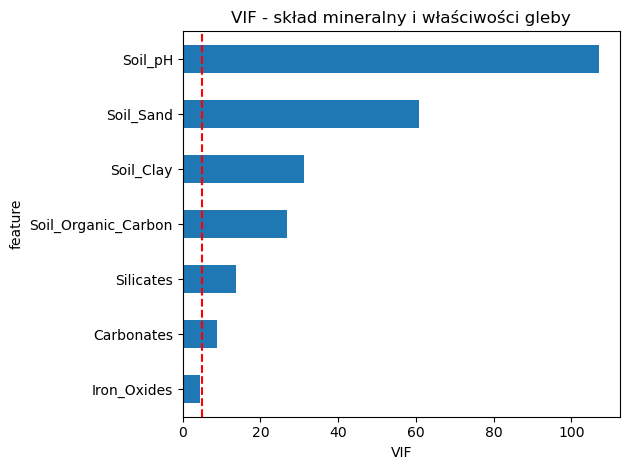

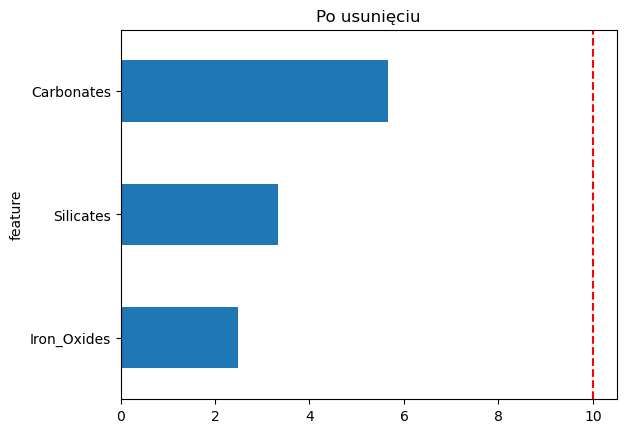

In [59]:
# Zmienne dotyczące składu mineralnego i właściwości gleby
sklad_mineralny = [
    "Silicates",
    "Carbonates",
    "Iron_Oxides",
    "Soil_Clay",
    "Soil_Sand",
    "Soil_pH",
    "Soil_Organic_Carbon"
]

df_mineral = df
# VIF przed usunięciem zmiennych
vif_przed = calculate_vif(df_mineral, sklad_mineralny)

print("VIF przed usunięciem:")
print(vif_przed)

# Wykres
vif_przed.sort_values(by="VIF").plot(
    kind="barh",
    x="feature",
    y="VIF",
    legend=False,
    title="VIF - skład mineralny i właściwości gleby"
)

plt.axvline(x=5, color="r", linestyle="--")
plt.xlabel("VIF")
plt.tight_layout()
plt.show()



df_cleaned = df_mineral.drop(columns=["Soil_pH", "Soil_Organic_Carbon", "Soil_Sand", "Soil_Clay"])
vif_po = calculate_vif(df_cleaned, sklad_mineralny)

#Wykres po
vif_po.sort_values(by="VIF").plot(kind="barh", x="feature", y="VIF", legend=False, title="Po usunięciu")
plt.axvline(x=10, color="r", linestyle="--")
df=df_cleaned


##

## Wskaźniki ekologiczne
1. NDVI (Normalized Difference Vegetation Index) wkaźnik gętosći zieleni. Od 1 do -1 Bujna roślinność 1 brak -1.
2. EVI (Enhanced Vegetation Index) ulepsozny NDVI porpzez dodanie światła niebieskiego
3. SAVI (Soil-Adjusted Vegetation Index) 
4. BSI (Bare Soil Index) wartość gołośći ziemi


VIF przed usunięciem:
   feature           VIF
0    SAVI  1.855178e+07
1    NDVI  1.855079e+07
2     BSI  2.818329e+00
3     EVI  1.056540e+00


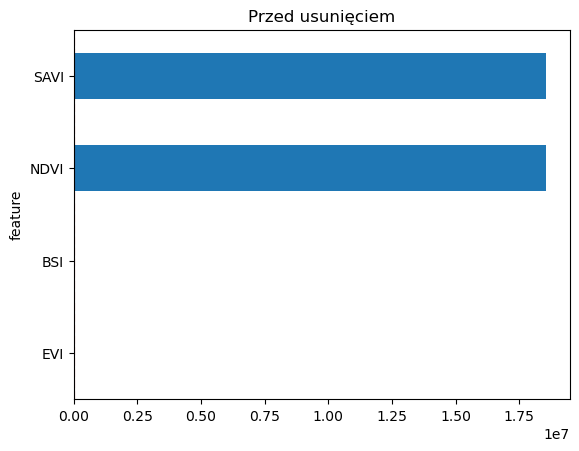

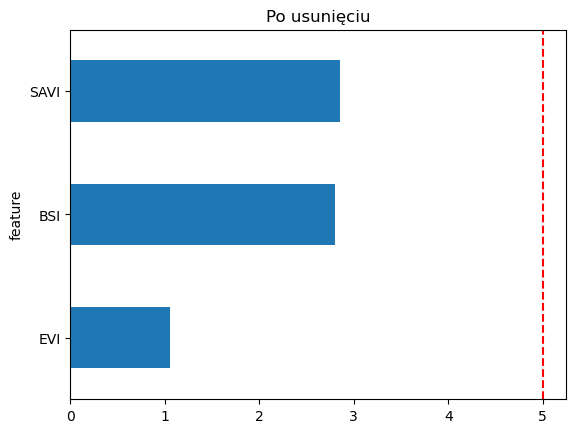

In [60]:
wskazniki_ekologiczne = ["NDVI", "EVI", "SAVI", "BSI"]

df_eco = df
vif_przed = calculate_vif(df, wskazniki_ekologiczne)
print("VIF przed usunięciem:\n", vif_przed)
vif_przed.sort_values(by="VIF").plot(kind="barh", x="feature", y="VIF", legend=False, title="Przed usunięciem")
plt.axvline(x=5, color="r", linestyle="--")
plt.show()

#Usuwmay NVDI bo to defatko to samo 
df_cleaned = df_eco.drop(columns=["NDVI", "NDWI"])
vif_po = calculate_vif(df_cleaned, wskazniki_ekologiczne)

#Wykres po
vif_po.sort_values(by="VIF").plot(kind="barh", x="feature", y="VIF", legend=False, title="Po usunięciu")
plt.axvline(x=5, color="r", linestyle="--")
df=df_cleaned


# Korelacje

Macierz korelacji:
                         wc2.1_30s_bio_10  wc2.1_30s_bio_6  wc2.1_30s_bio_9  \
wc2.1_30s_bio_10                 1.000000         0.934170         0.189260   
wc2.1_30s_bio_6                  0.934170         1.000000         0.334211   
wc2.1_30s_bio_9                  0.189260         0.334211         1.000000   
Aspect                          -0.019123        -0.009464         0.038102   
Curvature                       -0.146130        -0.101384        -0.013908   
EVI                              0.066018         0.059028         0.000954   
SAVI                             0.574369         0.507012        -0.056876   
BSI                             -0.563128        -0.481676         0.064320   
Silicates                        0.384083         0.345539         0.001253   
Carbonates                       0.516405         0.448893        -0.054134   
Iron_Oxides                     -0.624128        -0.553905         0.041567   
Slope                           -

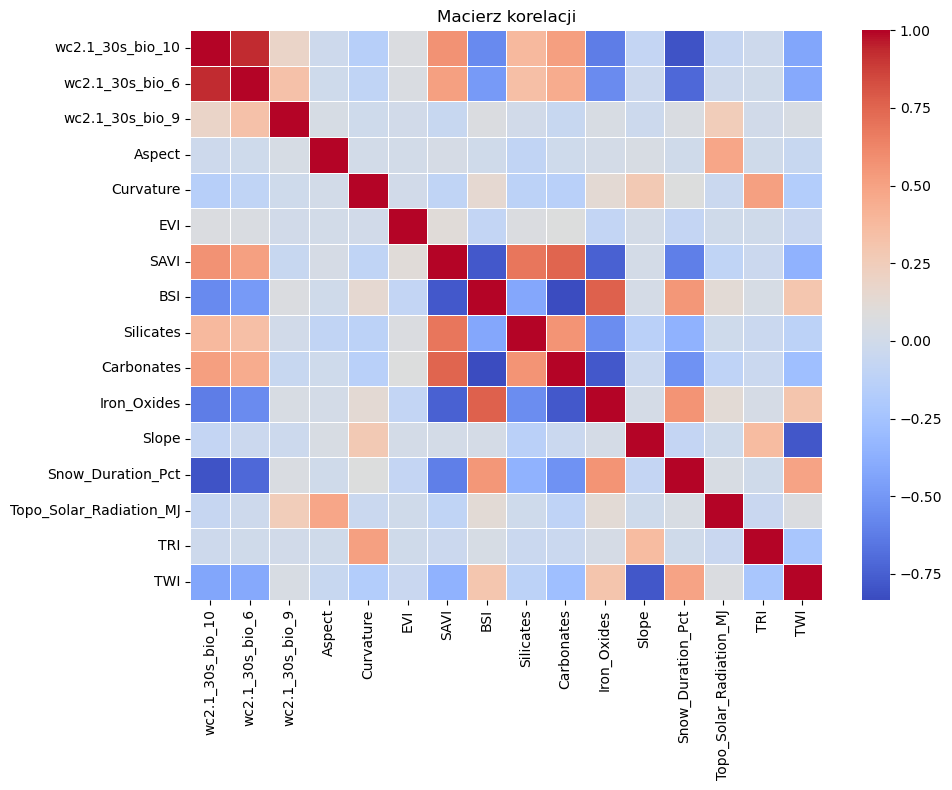

In [61]:
#Wybór tylko numerycznych kolumn
numeric_cols = df.select_dtypes(include=[np.number]).columns

#Wykluczenie zbanowanych kolumn
banned_cols = ["decimalLongitude", "decimalLatitude"]
features_cols = [col for col in numeric_cols if col not in banned_cols]

#Obliczenie macierzy korelacji dla odfiltrowanych danych
macierz_korelacji = df[features_cols].corr()
print("Macierz korelacji:")
print(macierz_korelacji)

#Generowanie heatmpa
plt.figure(figsize=(10, 8))
sns.heatmap(
    macierz_korelacji, 
    cmap='coolwarm', 
    linewidths=0.5 
)
plt.title("Macierz korelacji")
plt.tight_layout()
plt.savefig('plots/correlation_heatmap_features.png')
plt.show()



# VIF

VIF przed usunięciem:
                     feature         VIF
0                       TWI  192.832932
1           wc2.1_30s_bio_6   73.280263
2   Topo_Solar_Radiation_MJ   59.973505
3          wc2.1_30s_bio_10   51.195684
4                      SAVI   23.315270
5                 Silicates   19.126381
6         Snow_Duration_Pct    9.323686
7                Carbonates    9.290998
8                     Slope    8.555310
9                       BSI    7.605259
10                   Aspect    5.603248
11              Iron_Oxides    4.001248
12                Curvature    3.802019
13                      TRI    2.434801
14          wc2.1_30s_bio_9    1.767488
15                      EVI    1.057204


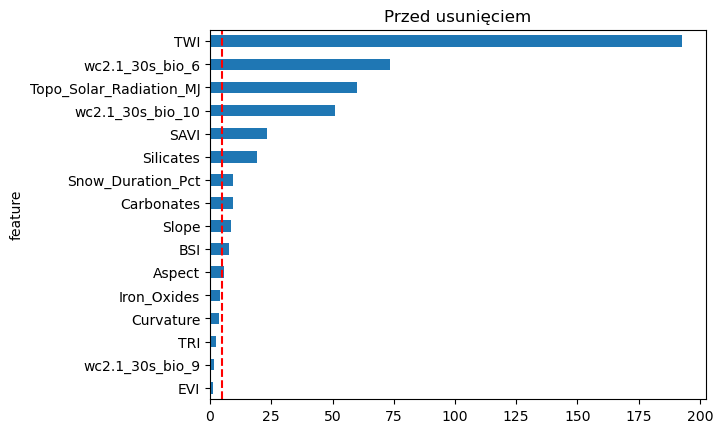

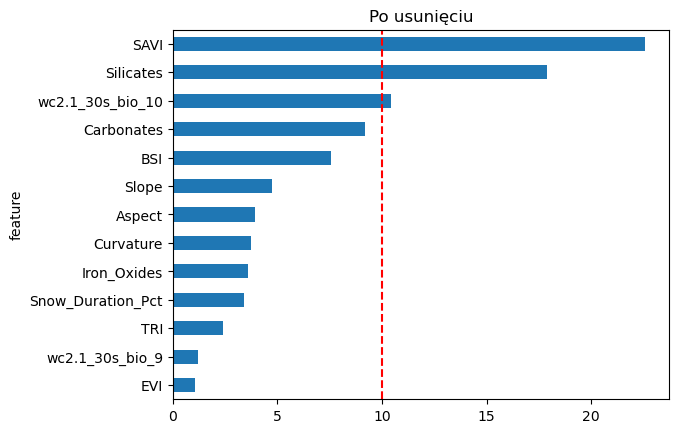

In [32]:
# 1. Lista cech początkowych (odfiltrowane ID i target)
cols_fetures = [col for col in df.columns if col not in ["decimalLongitude", "decimalLatitude", "gbifID", "true_present"]]

# Wyliczenie i wykres VIF przed zmianami
vif_przed = calculate_vif(df, cols_fetures)
print("VIF przed usunięciem:\n", vif_przed)

vif_przed.sort_values(by="VIF").plot(kind="barh", x="feature", y="VIF", legend=False, title="Przed usunięciem")
plt.axvline(x=5, color="r", linestyle="--")
plt.show()

# 1. Tworzymy listę zmiennych do wyrzucenia na podstawie naszej analizy
zmienne_do_usuniecia = [
    "TWI",                  # Gigantyczny VIF, dubluje Slope
    "wc2.1_30s_bio_19",
    "wc2.1_30s_bio_6",
    "Topo_Solar_Radiation_MJ"      # Dubluje temperature lata (bio_10), ważniejszą w Alpach
]

# 2. Tworzymy ostateczną listę cech dla modelu
final_features = [col for col in cols_fetures if col not in zmienne_do_usuniecia]

# Wyliczenie VIF na oryginalnym df, ale TYLKO dla oczyszczonej listy cech
vif_po = calculate_vif(df, final_features)

# Wykres po zmianach
vif_po.sort_values(by="VIF").plot(kind="barh", x="feature", y="VIF", legend=False, title="Po usunięciu")
plt.axvline(x=10, color="r", linestyle="--")
plt.show()

# UWAGA: Usunąłem linijkę df = df_cleaned. Oryginalny df zostaje nienaruszony!

# Random Forest

In [33]:
# 1. Czyszczenie danych i przygotowanie zmiennej objaśnianej (y)
df = df.dropna()
df["gbifID"] = df["gbifID"].astype(str)
df["true_present"] = (
    df["gbifID"].str.contains("pseudo", case=True).map({True: 0, False: 1})
)

# Filtrowanie wierszy z pseudoabsencją
df_pseudo_absence = df[df["true_present"] == 0]

# Definiowanie zmiennej objaśnianej (y)
y = df["true_present"]

# 2. Definiowanie zmiennych objaśniających (X) - używamy gotowej, przefiltrowanej listy cech
X = df[final_features]

# 3. Podział na zbiór treningowy i testowy
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

In [34]:
#siatka parametrów do sprawdzenia
param_grid = {
    'criterion': ['gini'],
    'max_depth': [None], 
    'min_samples_split': [2],     
    'max_features': [None],
    'class_weight': [None]
}

#konfiguracja grid
grid_search = GridSearchCV(estimator=DecisionTreeClassifier(random_state=0), 
                           param_grid=param_grid, 
                           cv=5, 
                           n_jobs=5, 
                           verbose=1, 
                           scoring='accuracy')

# grid serach
grid_search.fit(X_train, y_train)

# najlepsze
print(f"Najlepsze parametry: {grid_search.best_params_}")
print(f"Najlepszy wynik (accuracy): {grid_search.best_score_}")

# zapis
best_tree = grid_search.best_estimator_

#Sprawdzenie na zbiorze testowym
y_pred = best_tree.predict(X_test)
print(metrics.classification_report(y_test, y_pred))

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Najlepsze parametry: {'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'min_samples_split': 2}
Najlepszy wynik (accuracy): 0.8000117479212209
              precision    recall  f1-score   support

           0       0.81      0.79      0.80      3755
           1       0.79      0.82      0.81      3752

    accuracy                           0.80      7507
   macro avg       0.80      0.80      0.80      7507
weighted avg       0.80      0.80      0.80      7507



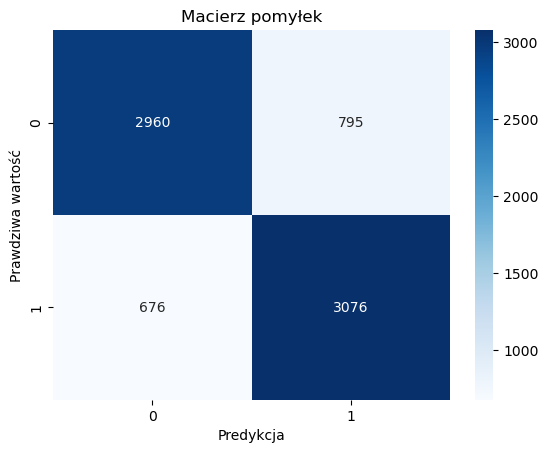

In [35]:
#Macierz pomyłek
cm = metrics.confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predykcja')
plt.ylabel('Prawdziwa wartość')
plt.title('Macierz pomyłek')
plt.show()

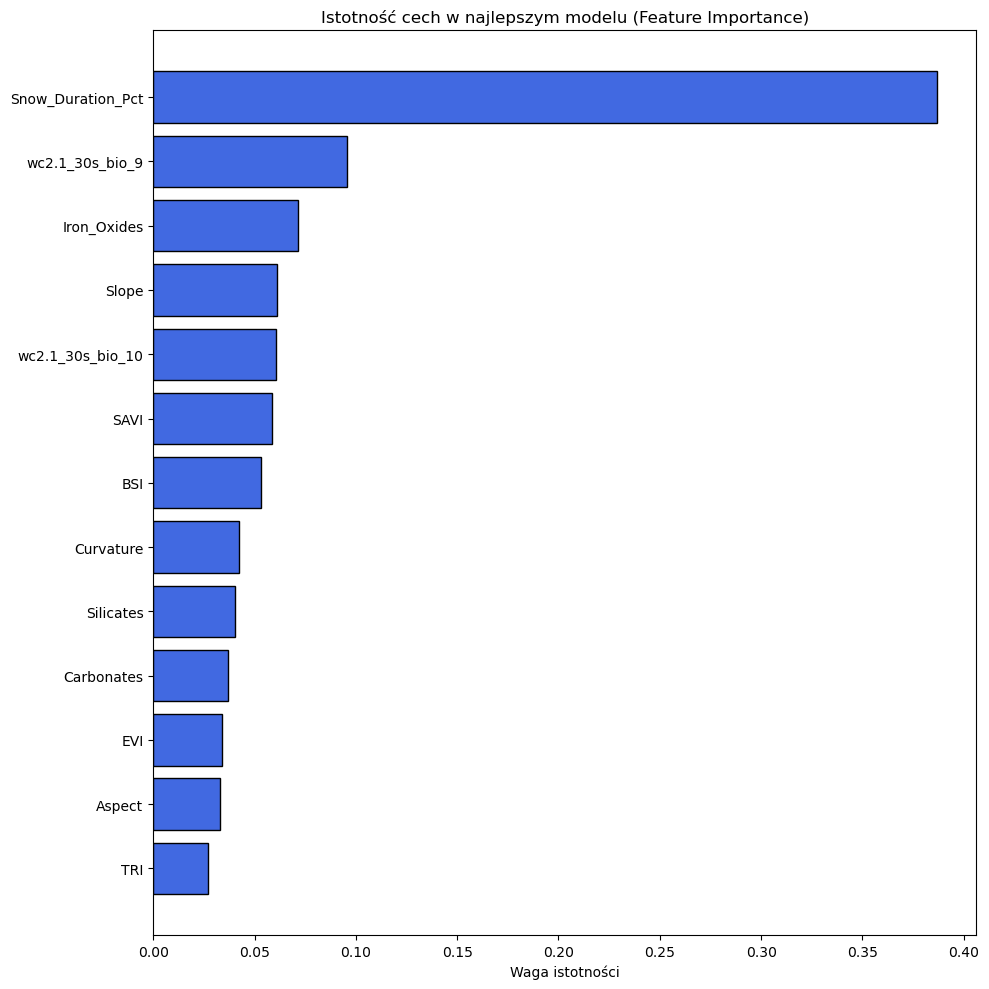

In [36]:
# Pobranie istotności cech z najlepszego estymatora Grid Search
# Zastąp 'grid_search' nazwą swojej zmiennej z GridSearchCV
najlepszy_model = grid_search.best_estimator_
importances = najlepszy_model.feature_importances_

# Tworzenie DataFrame z wynikami
istotnosc_df = pd.DataFrame({
    'Cecha': X.columns,
    'Istotnosc': importances
}).sort_values(by='Istotnosc', ascending=True)

# Wykres poziomy
plt.figure(figsize=(10, 10))
plt.barh(istotnosc_df['Cecha'], istotnosc_df['Istotnosc'], color='royalblue', edgecolor='black')
plt.title('Istotność cech w najlepszym modelu (Feature Importance)')
plt.xlabel('Waga istotności')
plt.tight_layout()
plt.show()


# RF

In [37]:
from sklearn.ensemble import RandomForestClassifier
#siatka parametrów do sprawdzenia
param_grid = {
    "n_estimators": [200],    
    "criterion": ["gini"],    
    "max_depth": [None],      
    "min_samples_split": [2],   
    "max_features": ["sqrt"],   
    "class_weight": ["balanced"] 
}

#konfiguracja grid
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=0, n_jobs=-1),
    param_grid=param_grid,
    cv=3,
    n_jobs=-1,
    verbose=2,
    scoring="f1",
)

# grid serach
grid_search.fit(X_train, y_train)

# najlepsze
print(f"Najlepsze parametry: {grid_search.best_params_}")
print(f"Najlepszy wynik (accuracy): {grid_search.best_score_}")

# zapis
best_tree = grid_search.best_estimator_

#Sprawdzenie na zbiorze testowym
y_pred = best_tree.predict(X_test)
print(metrics.classification_report(y_test, y_pred))



Fitting 3 folds for each of 1 candidates, totalling 3 fits


[CV] END class_weight=balanced, criterion=gini, max_depth=None, max_features=sqrt, min_samples_split=2, n_estimators=200; total time=  11.8s
[CV] END class_weight=balanced, criterion=gini, max_depth=None, max_features=sqrt, min_samples_split=2, n_estimators=200; total time=  11.9s
[CV] END class_weight=balanced, criterion=gini, max_depth=None, max_features=sqrt, min_samples_split=2, n_estimators=200; total time=  12.0s
Najlepsze parametry: {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 200}
Najlepszy wynik (accuracy): 0.8678078534849268
              precision    recall  f1-score   support

           0       0.89      0.83      0.86      3755
           1       0.84      0.90      0.87      3752

    accuracy                           0.86      7507
   macro avg       0.87      0.86      0.86      7507
weighted avg       0.87      0.86      0.86      7507



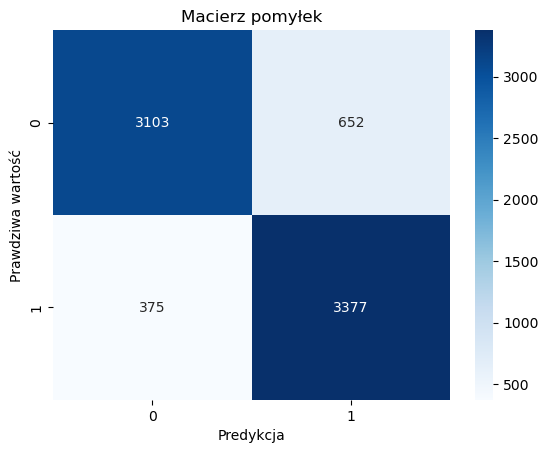

In [38]:
#Macierz pomyłek
cm = metrics.confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predykcja')
plt.ylabel('Prawdziwa wartość')
plt.title('Macierz pomyłek')
plt.show()

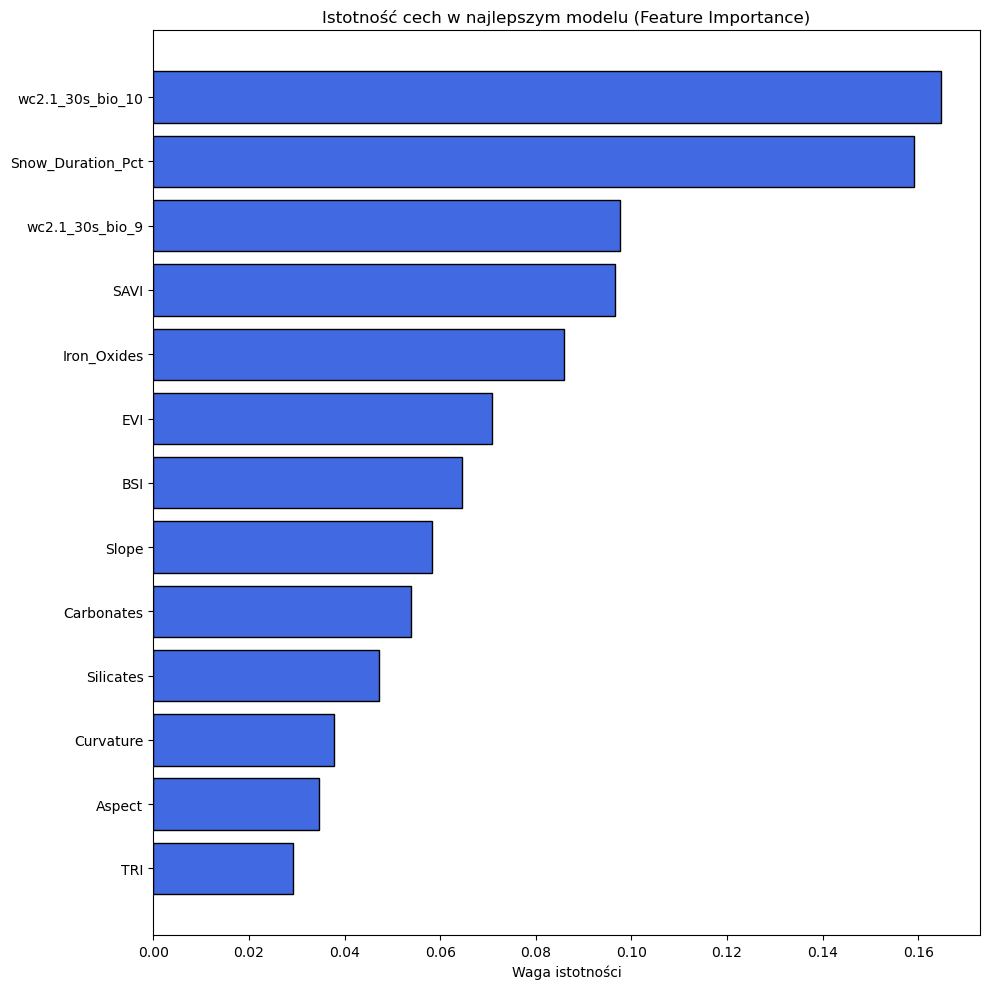

In [39]:
najlepszy_model = grid_search.best_estimator_
importances = najlepszy_model.feature_importances_

# Tworzenie DataFrame z wynikami
istotnosc_df = pd.DataFrame({
    'Cecha': X.columns,
    'Istotnosc': importances
}).sort_values(by='Istotnosc', ascending=True)

# Wykres poziomy
plt.figure(figsize=(10, 10))
plt.barh(istotnosc_df['Cecha'], istotnosc_df['Istotnosc'], color='royalblue', edgecolor='black')
plt.title('Istotność cech w najlepszym modelu (Feature Importance)')
plt.xlabel('Waga istotności')
plt.tight_layout()
plt.show()

# PCA

--- ISTOTNOŚĆ (WSPÓŁCZYNNIKI ODWZOROWANIA) ZMIENNYCH NA OSIACH PCA ---
                           PC1    PC2    PC3    PC4    PC5    PC6    PC7  \
wc2.1_30s_bio_10         0.322 -0.223  0.303 -0.311 -0.075  0.045 -0.110   
wc2.1_30s_bio_6          0.280 -0.265  0.350 -0.315 -0.009  0.006 -0.016   
wc2.1_30s_bio_9          0.049 -0.141  0.471 -0.131  0.264 -0.164  0.559   
Aspect                   0.013 -0.037  0.320  0.590  0.104 -0.037 -0.316   
Curvature               -0.009 -0.334 -0.228 -0.031  0.528 -0.208 -0.259   
EVI                      0.036 -0.005 -0.015  0.039  0.411  0.903  0.105   
SAVI                     0.406  0.123 -0.118  0.103  0.056 -0.031 -0.005   
BSI                     -0.376 -0.138  0.110 -0.135 -0.070  0.076 -0.124   
Silicates                0.343  0.197 -0.101  0.024  0.032 -0.028 -0.017   
Carbonates               0.404  0.152 -0.112  0.121  0.071 -0.073  0.123   
Iron_Oxides             -0.388 -0.089  0.105 -0.113 -0.056  0.059 -0.083   
Slope            

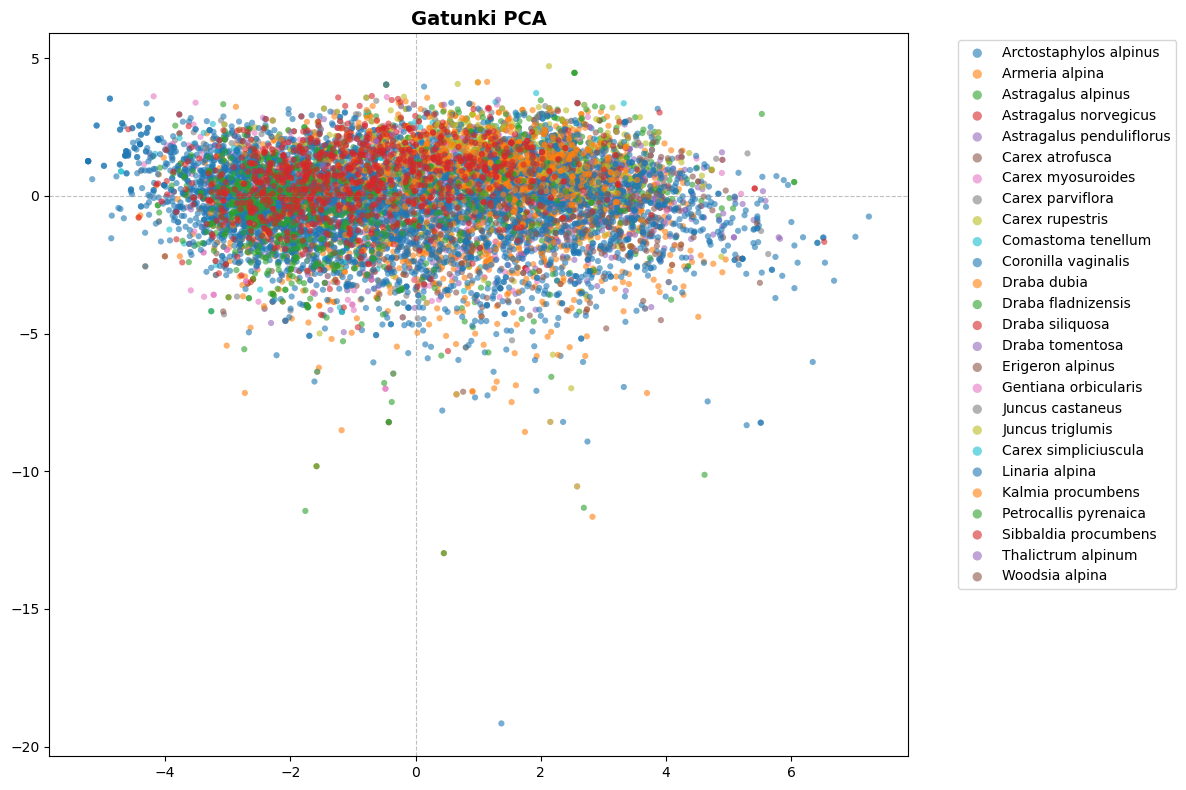

In [42]:
#informacje o gatunkach
meta =pd.read_csv("output/final_data/merged_all_species.csv")

# Konwersja kolumny gbifID na tekst w obu ramkach
df['gbifID'] = df['gbifID'].astype(str)
meta['gbifID'] = meta['gbifID'].astype(str)

#przygotowanie danych
df_full = pd.merge(df, meta[["gbifID", "species"]], on="gbifID", how="inner")

# Ignorujemy kolumny geograficzne i identyfikacyjne w analizie cech środowiskowych
banned_cols = ["gbifID", "species", "decimalLongitude", "decimalLatitude"]
features_cols = [col for col in df.columns if col not in banned_cols]

df_clean = df_full.dropna(subset=features_cols).reset_index(drop=True)
X = df_clean[features_cols]
y_species = df_clean["species"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#PCA z 9 składowymi, żeby mieć pełny obraz wpływu cech na przestrzeń cech
pca = PCA(n_components=9)
X_pca = pca.fit_transform(X_scaled)


# Obliczamy ładunki (loadings) - wpływ każdej zmiennej na PC1 i PC2
loadings = pd.DataFrame(
    pca.components_.T, columns=[f"PC{i+1}" for i in range(9)], index=features_cols
)

print("--- ISTOTNOŚĆ (WSPÓŁCZYNNIKI ODWZOROWANIA) ZMIENNYCH NA OSIACH PCA ---")
print(loadings.round(3))

#wykres PCA dla gatunków
plt.figure(figsize=(12, 8))

# Rysujemy punkty dla każdego gatunku osobno na jednym wykresie (plt)
for species_name in y_species.unique():
    mask = y_species == species_name
    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=species_name,
        alpha=0.6,
        s=20,
        edgecolors="none",
    )

plt.title(
    "Gatunki PCA",
    fontsize=14,
    fontweight="bold",
)

# Przemieszczamy legendę poza wykres
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", markerscale=1.5)
plt.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)

plt.tight_layout()
plt.show()

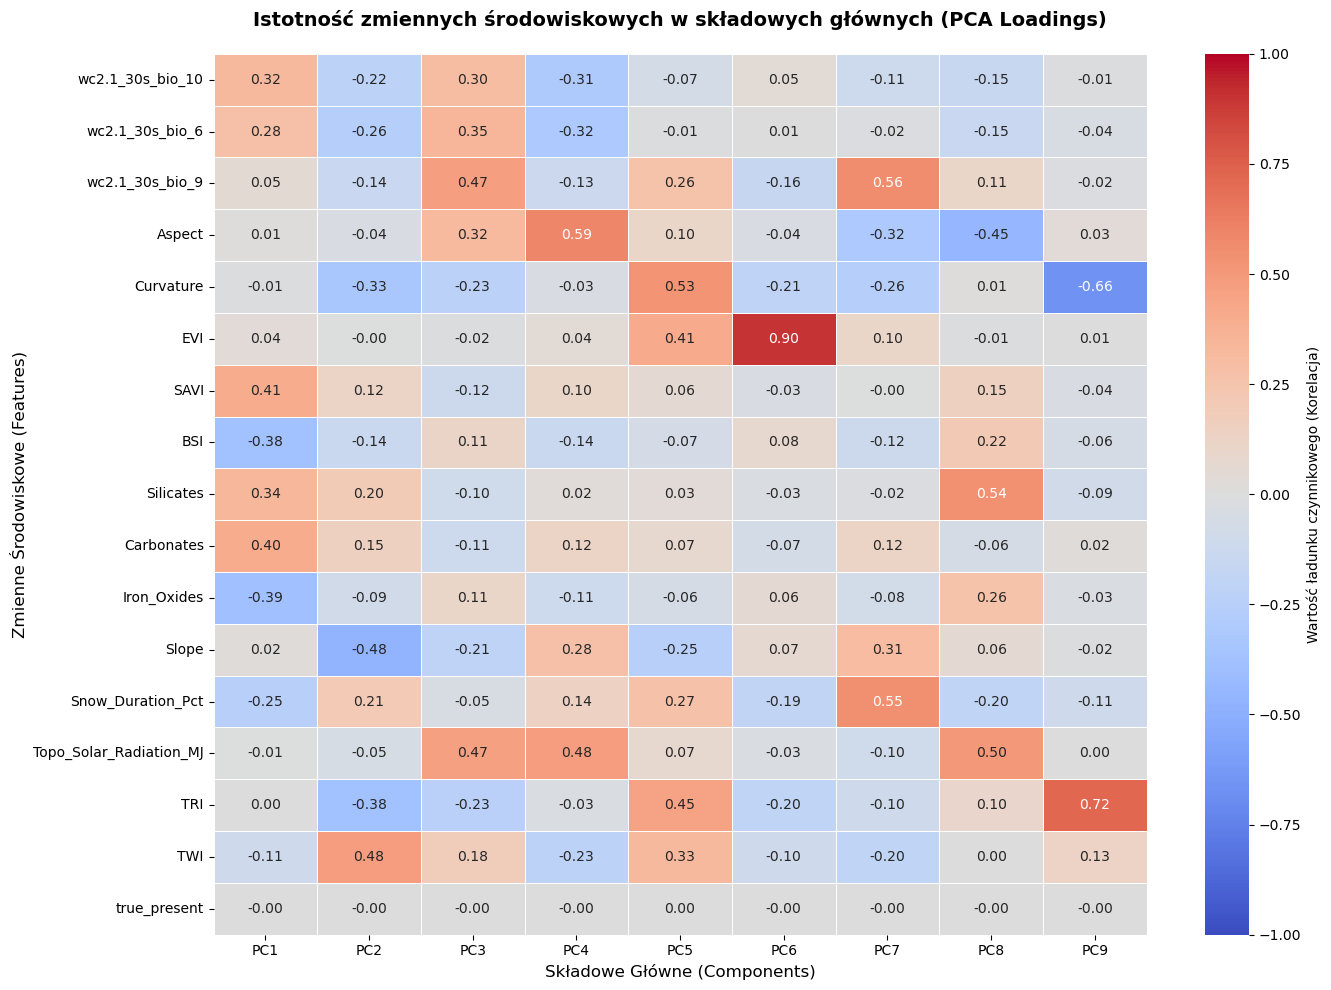

In [43]:
# HEATMAPA ŁADUNKÓW CZYNNIKOWYCH (LOADINGS)

plt.figure(figsize=(14, 10))

sns.heatmap(
    loadings,
    annot=True,  # Wyświetla wartości liczbowe w kwadratach
    fmt=".2f",  
    cmap="coolwarm",
    vmin=-1.0,
    vmax=1.0,
    linewidths=0.5,  # Delikatne linie siatki separujące komórki
    cbar_kws={"label": "Wartość ładunku czynnikowego (Korelacja)"},
)

plt.title(
    "Istotność zmiennych środowiskowych w składowych głównych (PCA Loadings)",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xlabel("Składowe Główne (Components)", fontsize=12)
plt.ylabel("Zmienne Środowiskowe (Features)", fontsize=12)

# Rotacja etykiet, żeby tekst na siebie nie nachodził
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Histogramy dla wartości

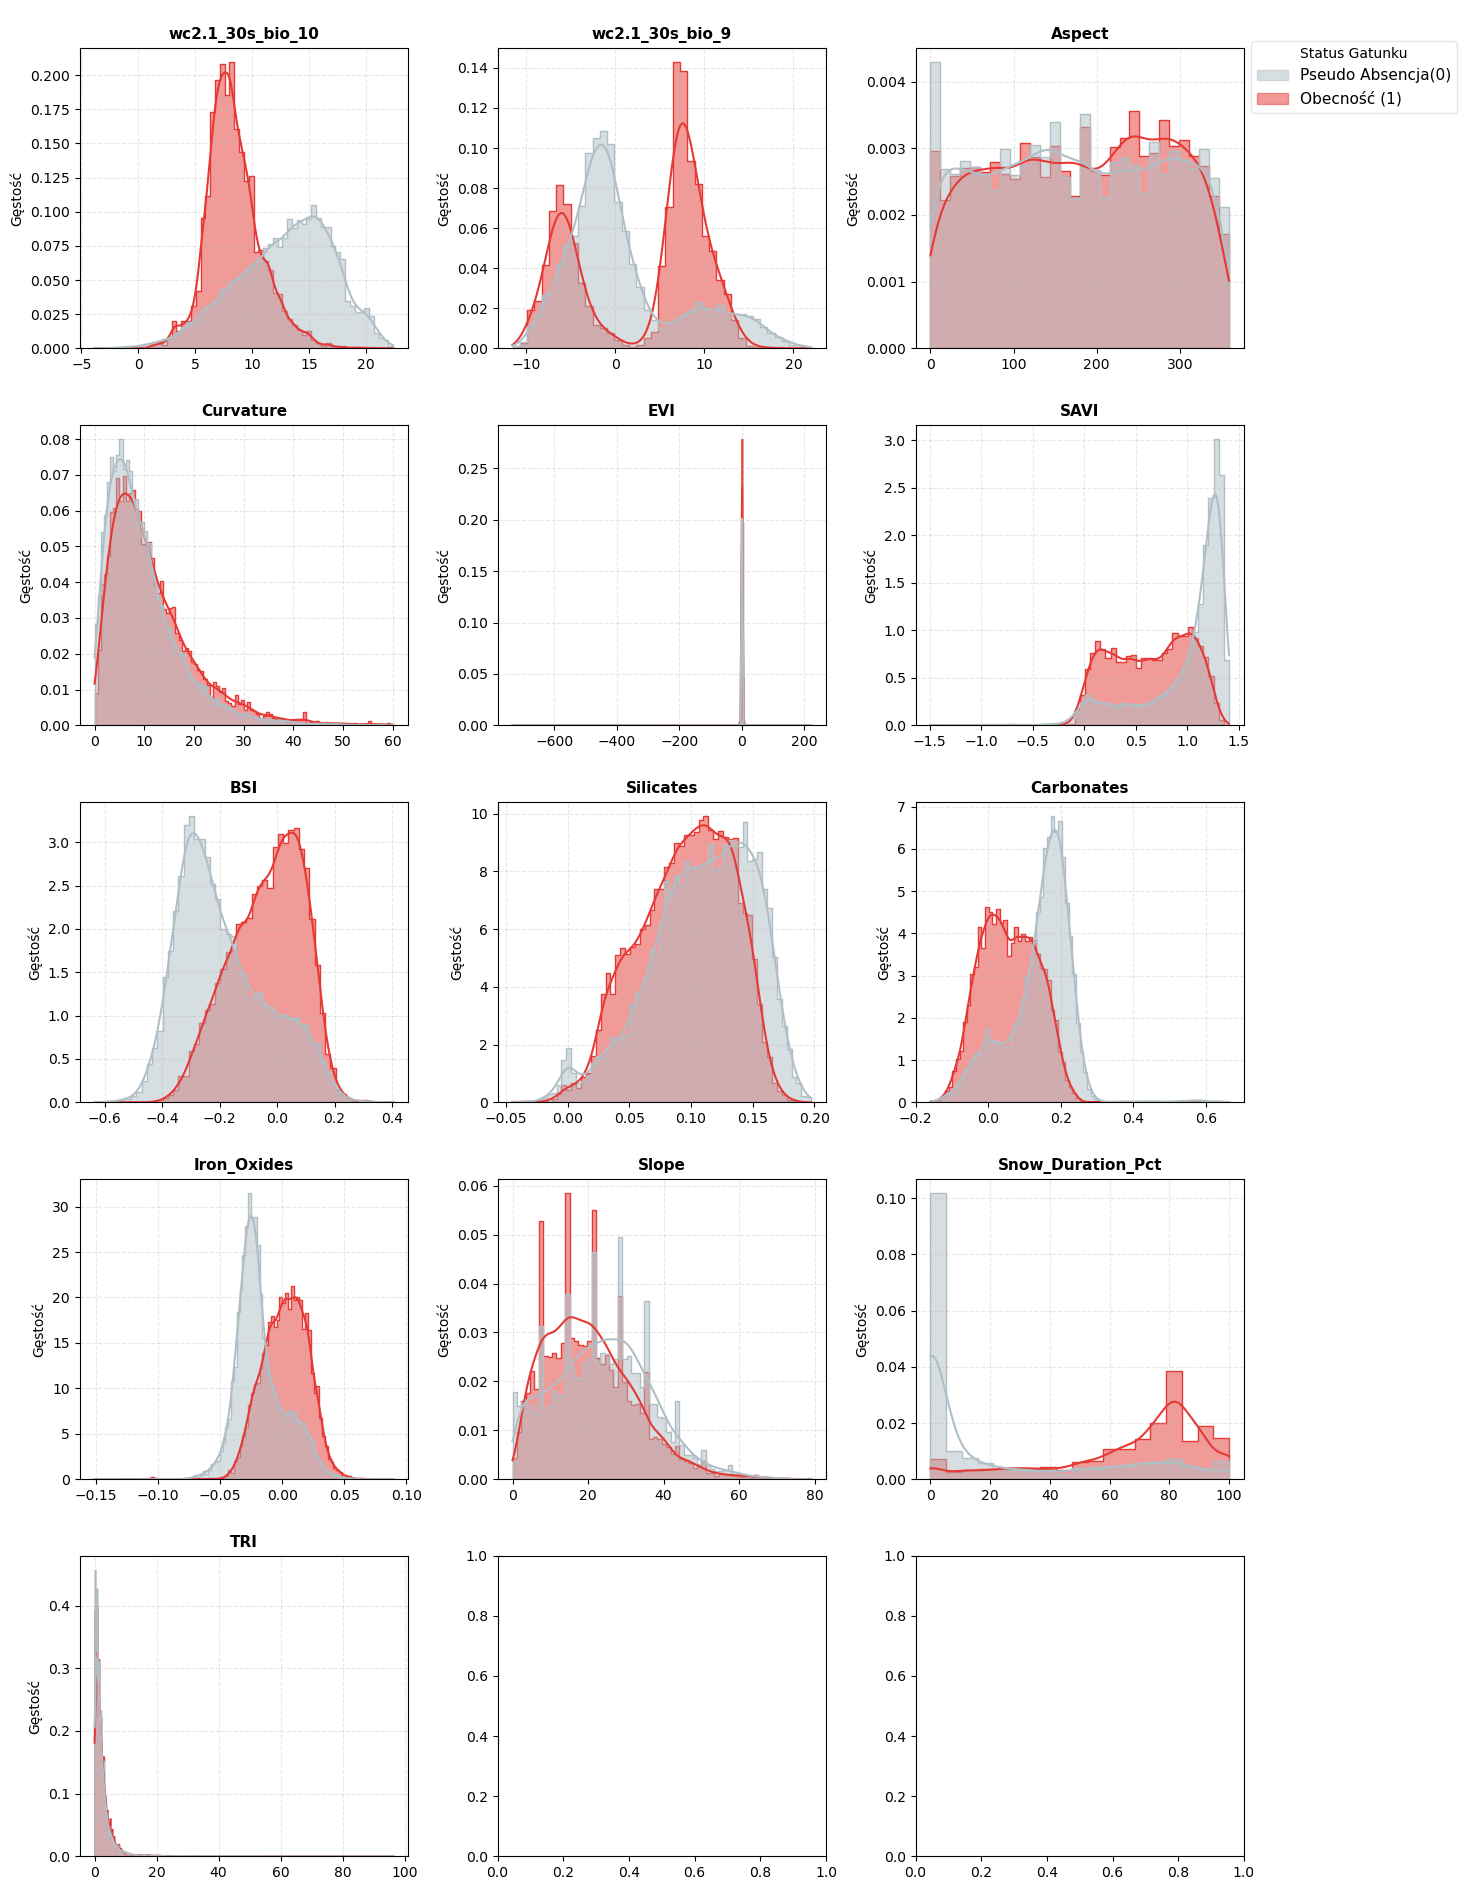

In [44]:
# Tworzenie kolumny z informacją o pseudoabsencji (0 = pseudo, 1 = prawdziwa obecność)
df["true_present"] = df["gbifID"].str.contains("pseudo", case=True).map({True: 0, False: 1})


# Liczymy saitkę wykresów
zmienne_do_wykresu = final_features
n_cols = 3
n_rows = math.ceil(len(zmienne_do_wykresu) / n_cols)

# Inicjalizacja płótna
fig, axes = plt.subplots(
    n_rows, n_cols, figsize=(n_cols * 5, n_rows * 3.8), sharey=False
)
axes = axes.flatten()

# Kolory dla zachowania spójności
kolory = {0: "#b0bec5", 1: "#e53935"}

#  Pętla rysująca histogramy
for i, col in enumerate(zmienne_do_wykresu):
    ax = axes[i]

    sns.histplot(
        data=df,
        x=col,
        hue="true_present",
        palette=kolory,
        alpha=0.5,
        kde=True,
        element="step",
        stat="density",
        common_norm=False,
        legend=False,  # Wyłączamy legendę na pojedynczym wykresie
        ax=ax,
    )

    # Stylizacja pojedynczego wykresu
    ax.set_title(f"\n{col}", fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Gęstość")
    ax.grid(True, linestyle="--", alpha=0.3)


# Globalna legenda
legenda_absencja = mpatches.Patch(
    color=kolory[0], alpha=0.5, label="Pseudo Absencja(0)"
)
legenda_obecnosc = mpatches.Patch(
    color=kolory[1], alpha=0.5, label="Obecność (1)"
)

# Zapisujemy legendę
leg = fig.legend(
    handles=[legenda_absencja, legenda_obecnosc],
    loc="upper right",
    bbox_to_anchor=(0.98, 0.98),
    title="Status Gatunku",  
    fontsize=11,
    frameon=True,
    facecolor="white",
    edgecolor="#e0e0e0",
)

# Dopasowanie układu z marginesem na prawą legendę
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.savefig('plots/feature_histograms.png')
plt.show()

In [46]:
df.to_csv("csv/selected_features.csv")